# LeetCode #31: Next Permutation

https://leetcode.com/problems/next-permutation/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n! \cdot n)$ | $O(n)$ |
| **Optimal: Three-Step Reverse ★** | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Generate all permutations of the array, sort them lexicographically, find the current permutation, and return the next one. Factorial time and space — completely impractical for $n > 8$.

### Optimal: Three-Step Reverse ★
1. Scan right-to-left to find the rightmost index $i$ where `nums[i] < nums[i+1]` (the "descent pivot").
2. Scan right-to-left again to find the rightmost index $j$ where `nums[j] > nums[i]`; swap them.
3. Reverse the suffix `nums[i+1:]` to obtain the smallest possible ordering of those elements.
If no pivot exists, the array is the largest permutation — just reverse the entire array to wrap to the smallest.

**Constraints:**
* $1 \leq \text{nums.length} \leq 100$
* $0 \leq \text{nums}[i] \leq 100$
* Must be done in-place with $O(1)$ extra memory.


## Solutions

### C#

In [ ]:
public class Solution {
    public void NextPermutation(int[] nums) {
        int n = nums.Length, i = n - 2;
        // Step 1: Find the rightmost element smaller than its right neighbor (pivot)
        while (i >= 0 && nums[i] >= nums[i + 1]) i--;

        if (i >= 0) {
            // Step 2: Swap the pivot with the smallest element to its right that is larger
            int j = n - 1;
            while (nums[j] <= nums[i]) j--;
            (nums[i], nums[j]) = (nums[j], nums[i]);
        }

        // Step 3: Reverse the suffix to form the smallest ordering after the pivot
        int left = i + 1, right = n - 1;
        while (left < right) {
            (nums[left], nums[right]) = (nums[right], nums[left]);
            left++;
            right--;
        }
    }
}

### Python

In [ ]:
class Solution:
    def next_permutation(self, nums: list[int]) -> None:
        n = len(nums)
        i = n - 2
        # Step 1: Find the rightmost element smaller than its right neighbor (pivot)
        while i >= 0 and nums[i] >= nums[i + 1]:
            i -= 1

        if i >= 0:
            # Step 2: Swap the pivot with the smallest element to its right that is larger
            j = n - 1
            while nums[j] <= nums[i]:
                j -= 1
            nums[i], nums[j] = nums[j], nums[i]

        # Step 3: Reverse the suffix to form the smallest ordering after the pivot
        nums[i + 1:] = reversed(nums[i + 1:])

### Go

In [ ]:
func nextPermutation(nums []int) {
    n := len(nums)
    i := n - 2
    // Step 1: Find the rightmost element smaller than its right neighbor (pivot)
    for i >= 0 && nums[i] >= nums[i+1] {
        i--
    }

    if i >= 0 {
        // Step 2: Swap the pivot with the smallest element to its right that is larger
        j := n - 1
        for nums[j] <= nums[i] {
            j--
        }
        nums[i], nums[j] = nums[j], nums[i]
    }

    // Step 3: Reverse the suffix to form the smallest ordering after the pivot
    left, right := i+1, n-1
    for left < right {
        nums[left], nums[right] = nums[right], nums[left]
        left++
        right--
    }
}

### Rust

In [ ]:
impl Solution {
    pub fn next_permutation(nums: &mut Vec<i32>) {
        let n = nums.len();
        // Step 1: Find the rightmost element smaller than its right neighbor (pivot)
        let mut i = n as i64 - 2;
        while i >= 0 && nums[i as usize] >= nums[i as usize + 1] {
            i -= 1;
        }

        if i >= 0 {
            // Step 2: Swap the pivot with the smallest element to its right that is larger
            let mut j = n as i64 - 1;
            while nums[j as usize] <= nums[i as usize] {
                j -= 1;
            }
            nums.swap(i as usize, j as usize);
        }

        // Step 3: Reverse the suffix to form the smallest ordering after the pivot
        nums[i as usize + 1..].reverse();
    }
}

## Example Scenarios

### 1. Common Case
**Input:** `nums = [1, 2, 3]`
Scan from the right for the pivot: index 1 (value `2 < 3`). Swap the pivot with the smallest element to its right that is larger (`3`), then reverse the suffix after the pivot. Result: `[1, 3, 2]`.

### 2. Slightly Complex
**Input:** `nums = [1, 2, 3, 6, 5, 4]`
Pivot is index 2 (value `3`), since `3 < 6` but the tail `6,5,4` is descending. Swap `3` with `4` (rightmost value `> 3`) to get `[1, 2, 4, 6, 5, 3]`, then reverse the suffix `[6, 5, 3] \rightarrow [3, 5, 6]`. Result: `[1, 2, 4, 3, 5, 6]`.

### 3. Edge Case: Time Factor
**Input:** `nums = [3, 2, 1]`
The whole array is descending, so the pivot scan walks all the way to `i = -1` (the current permutation is the largest). With no pivot, the entire array is reversed to the smallest permutation. Result: `[1, 2, 3]`. The scan still costs $O(n)$.

### 4. Edge Case: Space Factor
**Input:** `nums = [2, 2, 0, 4, 3, 1]`
Pivot is index 2 (value `0`). Swap with `1` and reverse the suffix `[4, 3, 0] \rightarrow [0, 3, 4]`, giving `[2, 2, 1, 0, 3, 4]`. Duplicates and a long suffix are handled entirely in place — $O(1)$ extra space, no copy.

### 5. Almost-Impossible but Plausible
**Input:** `nums = [1]`
A single element has no pivot and no suffix to reverse. The next permutation of a one-element array is itself. Result: `[1]` — the algorithm must not index out of bounds.


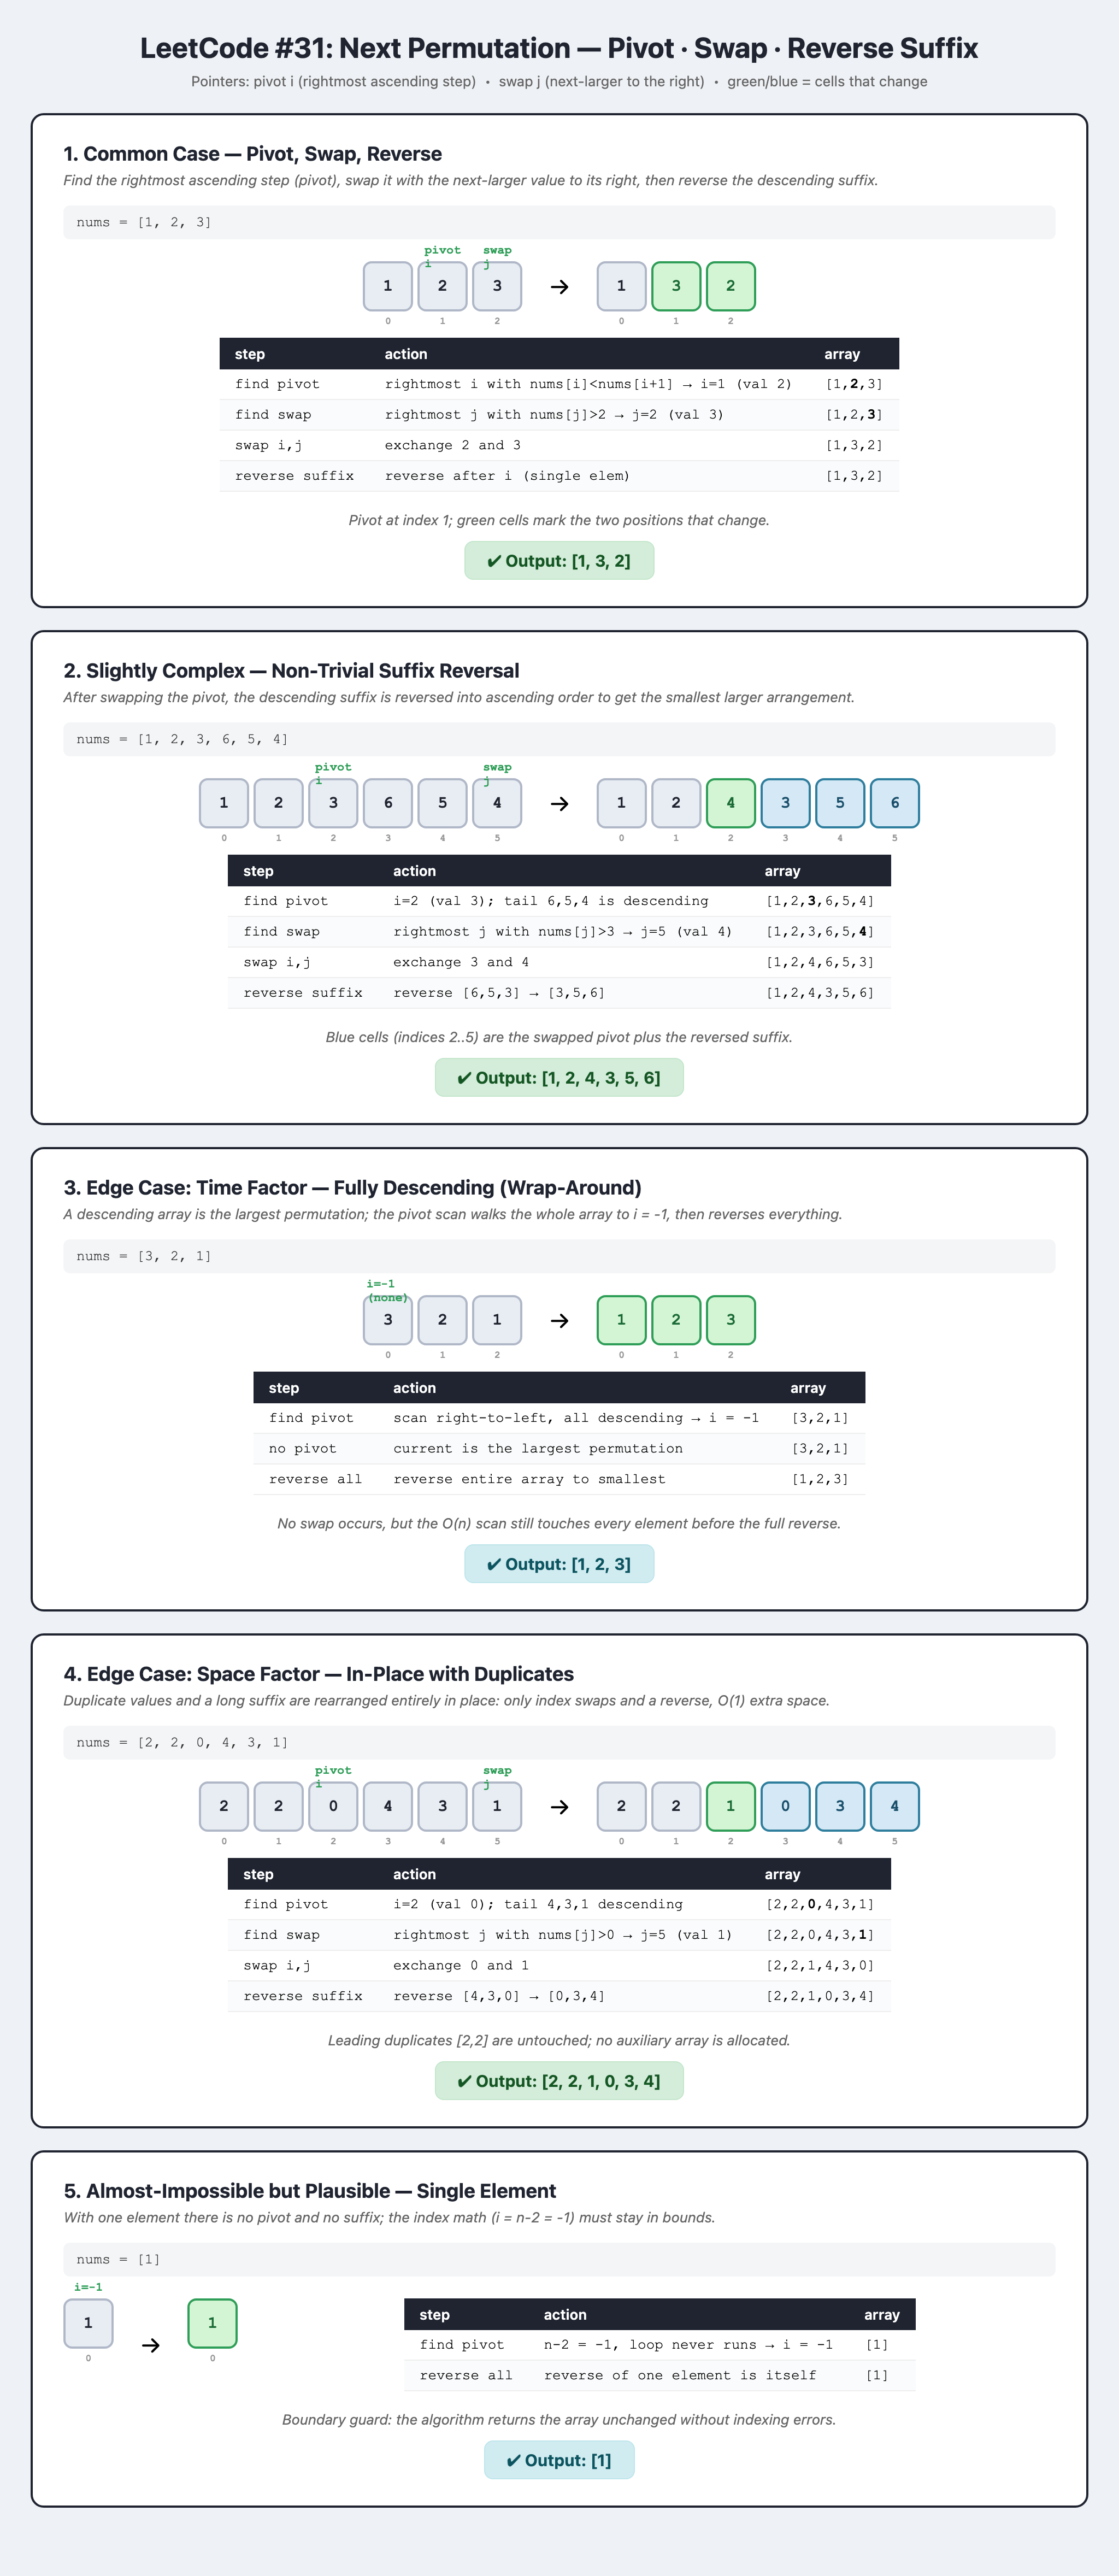